# M2.2 · 基本面与事件因子

> 基本面因子从估值、盈利、成长等公司层面信息获取超额，通常与价量因子低相关、换手低、容量大。
> 本节用 PE/PB/市值构造价值与基本面变化因子，并用价量代理事件因子，评估 IC/IR。

## 一、因子逻辑

| 类别 | 因子 |
|---|---|
| 价值/估值 | EP、BP、价值综合、估值历史分位 |
| 基本面变化 | EP 改善、BP 改善、规模 |
| 事件（价量代理） | 异常放量、事件跳空、异动反转 |

> 代码在 factor_lab2.bfactors；真实事件需公告/研报数据，这里给价量代理。

## 二、加载数据并构造因子

In [1]:
import sys, numpy as np, pandas as pd
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
from l2.config import load_universe
import config
from factor_lab2 import bfactors
from factor_lab.evaluate import ic_series, ic_summary, fwd_returns
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = load_universe('hs300')
raw = D.features(codes, ['$open','$close','$volume','$mkt_cap_ard',
                         '$pe_ttm','$pb_lf'],
                 start_time='2018-01-01', freq='day')
op=raw['$open'].unstack('instrument'); cl=raw['$close'].unstack('instrument')
vo=raw['$volume'].unstack('instrument'); mk=raw['$mkt_cap_ard'].unstack('instrument')
pe=raw['$pe_ttm'].unstack('instrument'); pb=raw['$pb_lf'].unstack('instrument')
bf = bfactors.build_bf_factors(cl, op, vo, mk, pe, pb)
print('构造基本面/事件因子 %d 个:' % len(bf)); print(list(bf.keys()))

[26736:MainThread](2026-11-05 16:35:11,603) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[26736:MainThread](2026-11-05 16:35:13,571) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[26736:MainThread](2026-11-05 16:35:13,573) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


构造基本面/事件因子 10 个:
['EP 盈利收益率', 'BP 账面市值比', '价值综合', '估值低分位', 'EP 改善20', 'BP 改善20', 'A股市值规模', '异常放量', '事件跳空', '异动反转']


## 三、IC/IR 评估

In [2]:
fwd1 = fwd_returns(cl, 1)
rows = []
for name, fac in bf.items():
    s = ic_summary(ic_series(fac, fwd1))
    rows.append({'因子': name, 'IC': s['IC均值'], 'IR': s['IR'], '胜率': s['IC胜率']})
res = pd.DataFrame(rows).set_index('因子').sort_values('IC', ascending=False)
print(res.round(4).to_string())

              IC      IR      胜率
因子                              
异动反转      0.0255  0.1386  0.5667
价值综合      0.0178  0.0681  0.5290
BP 账面市值比  0.0176  0.0686  0.5332
EP 盈利收益率  0.0175  0.0712  0.5294
异常放量      0.0143  0.1021  0.5427
BP 改善20   0.0104  0.0545  0.5179
EP 改善20   0.0087  0.0493  0.5127
估值低分位     0.0067  0.0436  0.5161
A股市值规模    0.0015  0.0082  0.5089
事件跳空     -0.0077 -0.0501  0.4787


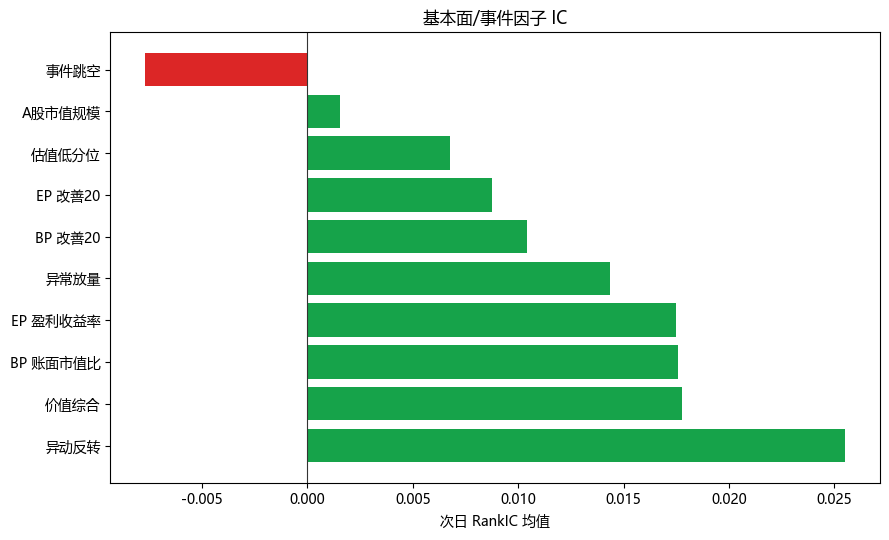

In [3]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(9,5.5))
colors = ['#dc2626' if x<0 else '#16a34a' for x in res['IC']]
ax.barh(res.index, res['IC'], color=colors)
ax.axvline(0, color='#333', lw=0.8)
ax.set_xlabel('次日 RankIC 均值'); ax.set_title('基本面/事件因子 IC')
plt.tight_layout(); plt.show()

## 四、价值因子的长周期特性

In [4]:
# 价值/规模因子通常是慢因子，看长持有期 IC
from factor_lab.evaluate import ic_decay
dec = ic_decay(bf['A股市值规模'], cl, ks=(1,5,20,60,120))
print('规模因子 IC 随持有期变化:')
print(dec.round(4).to_string())

规模因子 IC 随持有期变化:
       IC均值      IR    IC胜率
持有期                        
1    0.0015  0.0082  0.5089
5    0.0159  0.0838  0.5164
20   0.0482  0.2470  0.5922
60   0.0908  0.5224  0.6824
120  0.1351  0.8374  0.7902


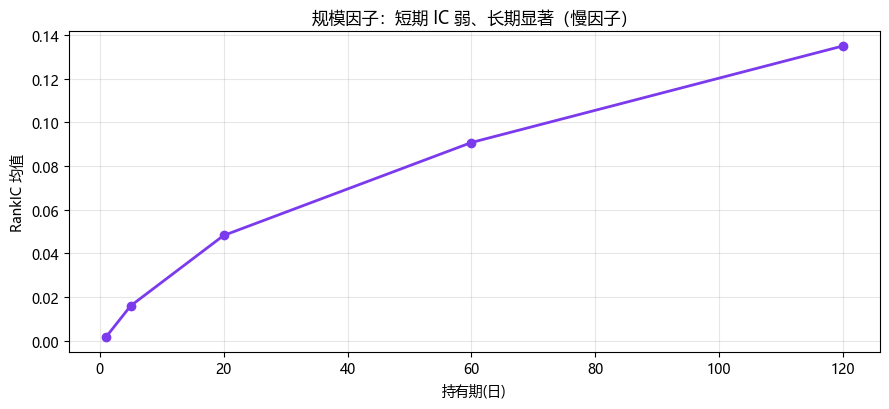

In [5]:
fig, ax = plt.subplots(figsize=(9,4.2))
ax.plot(dec.index, dec['IC均值'], 'o-', lw=2, color='#7c3aed')
ax.set_xlabel('持有期(日)'); ax.set_ylabel('RankIC 均值')
ax.set_title('规模因子：短期 IC 弱、长期显著（慢因子）')
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 五、事件因子的特点与局限

- 异常放量、跳空、异动是事件的价量代理，真实事件（业绩、并购、增减持）需公告数据；
- 事件因子往往短期有效、衰减快，需注意样本量和过拟合；
- 基本面因子换手低、容量大，适合作为组合的稳定底仓。

## 六、小结与面试要点

- 价值（EP/BP）、估值分位、基本面变化构成基本面因子；事件用价量代理。
- 基本面因子低换手、大容量，规模/价值偏慢因子，与价量因子低相关。

**面试高频：**
- EP 和 BP 分别是什么？（答：盈利收益率1/PE、账面市值比1/PB，价值因子）
- 为什么基本面因子容量大？（答：换手低、信号稳定，大资金可承载）
- 怎么用估值历史分位做因子？（答：当前PE在历史中的分位，越低越便宜取负向）
- 事件因子有什么风险？（答：样本少、衰减快、易过拟合，需公告数据支撑）

## 动手练习
1. 评估全部基本面因子并排序；
2. 对比价值因子在短/长持有期的 IC；
3. 设计一个真实事件因子（如业绩超预期）的数据与检验流程。

---
下一节 **M2.3 因子正交与降维**。